In [1]:
# ========== ONE CELL: Unzip then apply enhancement to all images and create enhanced zip ==========
# EDIT THESE PATHS BEFORE RUNNING
ZIP_PATH = "/content/drive/MyDrive/n.zip"   # path to your original zip on Drive
EXTRACT_DIR = "/content/unzipped_images"                     # where the zip will be extracted
ENHANCED_ROOT = "/content/enhanced_images"                   # where enhanced images will be written
OUTPUT_ZIP_NAME = "/content/drive/MyDrive/skin_lesion_dataset_enhanced"  # final zip (without .zip)
NUM_WORKERS = 8     # parallel processes for image processing (<= CPU cores)
FORCE_UNZIP = False # set True to re-extract ZIP even if EXTRACT_DIR exists

# ===== Parameter set (from your result) =====
best = {
  "index": 2,
  "fitness_subset": 2.1100515198045153,
  "fitness_full": 2.132937591983258,
  "params": {
    "clahe_prob": 1.0,
    "clahe_clip": 8.0,
    "clahe_tile": [32, 32],
    "brightness": 1.2759188517019069,
    "contrast": 0.9493431339288161,
    "saturation": 1.6998323538384155,
    "hue": 0.16715379261674557,
    "blur_sigma": 0.3270978297105927,
    "sharpen": 2.0,
    "noise_std": 0.03727316957180657,
    "unsharp_prob": 1.0
  }
}

# ---------------- Implementation ----------------
import os, zipfile, shutil, math, sys
from pathlib import Path
from multiprocessing import Pool, cpu_count
from functools import partial
from tqdm import tqdm

# Attempt to mount Drive (Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception:
    pass

# Install dependencies if missing
import importlib
if importlib.util.find_spec("cv2") is None:
    print("Installing dependencies (opencv, pillow, numpy, tqdm)...")
    os.system("pip install -q opencv-python-headless Pillow numpy tqdm")

import cv2
import numpy as np
from PIL import Image, ImageEnhance

# 1) unzip (if needed or forced)
extract_path = Path(EXTRACT_DIR)
if extract_path.exists() and FORCE_UNZIP:
    print(f"FORCE_UNZIP=True: removing existing folder {extract_path} ...")
    shutil.rmtree(extract_path)

if not extract_path.exists():
    print(f"Extracting {ZIP_PATH} -> {extract_path} ... (may take a while)")
    extract_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(str(extract_path))
    print("Extraction complete.")
else:
    print(f"Using existing extracted folder: {extract_path}")

# 2) collect image paths
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tiff")
all_paths = [str(p) for p in extract_path.rglob("*") if p.suffix.lower() in EXTS]
all_paths.sort()
n_images = len(all_paths)
print(f"Found {n_images} images in {extract_path}")

if n_images == 0:
    raise FileNotFoundError("No images found under " + str(extract_path))

# 3) prepare output mirroring folder
enh_root = Path(ENHANCED_ROOT)
enh_root.mkdir(parents=True, exist_ok=True)
print(f"Enhanced images will be written under: {enh_root}")

# 4) decode params & helpers
params = best["params"]
clahe_prob = float(params.get("clahe_prob", 0.0))
clahe_clip = float(params.get("clahe_clip", 2.0))
clahe_tile = tuple(params.get("clahe_tile", (8,8)))
brightness_f = float(params.get("brightness", 1.0))
contrast_f = float(params.get("contrast", 1.0))
saturation_f = float(params.get("saturation", 1.0))
hue_f = float(params.get("hue", 0.0))
blur_sigma = float(params.get("blur_sigma", 0.0))
sharpen_amt = float(params.get("sharpen", 0.0))
noise_std = float(params.get("noise_std", 0.0))
unsharp_prob = float(params.get("unsharp_prob", 0.0))

def sigma_to_ksize(sigma):
    sigma = float(sigma)
    if sigma <= 0:
        return 0
    k = max(3, int(2 * round(3 * sigma) + 1))
    if k % 2 == 0:
        k += 1
    return k

def apply_clahe_bgr(img_bgr, clip=clahe_clip, tile=clahe_tile):
    # Expect img_bgr as uint8 BGR
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, A, B = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip), tileGridSize=tile)
    L2 = clahe.apply(L)
    lab2 = cv2.merge((L2, A, B))
    return cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)

def color_jitter_bgr(img_bgr, brightness=brightness_f, contrast=contrast_f, saturation=saturation_f, hue=hue_f):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    pil = Image.fromarray(rgb)
    if abs(brightness - 1.0) > 1e-6:
        pil = ImageEnhance.Brightness(pil).enhance(float(brightness))
    if abs(contrast - 1.0) > 1e-6:
        pil = ImageEnhance.Contrast(pil).enhance(float(contrast))
    if abs(saturation - 1.0) > 1e-6:
        pil = ImageEnhance.Color(pil).enhance(float(saturation))
    arr = np.array(pil)
    if abs(hue) > 1e-6:
        hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[...,0] = (hsv[...,0] + float(hue) * 180.0) % 180.0
        arr = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)

def gaussian_blur(img_bgr, sigma):
    s = float(sigma)
    if s <= 0:
        return img_bgr
    k = sigma_to_ksize(s)
    if k <= 0:
        return img_bgr
    return cv2.GaussianBlur(img_bgr, (k,k), sigmaX=s, sigmaY=s)

def unsharp_mask(img_bgr, amount=sharpen_amt):
    amt = float(amount)
    if amt <= 0:
        return img_bgr
    blurred = cv2.GaussianBlur(img_bgr, (0,0), sigmaX=1.0)
    return cv2.addWeighted(img_bgr, 1.0 + amt, blurred, -amt, 0)

def add_gaussian_noise(img_bgr, std):
    st = float(std)
    if st <= 0:
        return img_bgr
    noise = np.random.normal(0, st * 255.0, img_bgr.shape).astype(np.float32)
    out = img_bgr.astype(np.float32) + noise
    return np.clip(out, 0, 255).astype(np.uint8)

# 5) per-image processing function
def process_one(path):
    try:
        p = Path(path)
        rel = p.relative_to(extract_path)
        out_p = enh_root.joinpath(rel)
        out_p.parent.mkdir(parents=True, exist_ok=True)

        img = cv2.imread(path)
        if img is None:
            return (str(path), False, "read_failed")

        # 1: CLAHE blended with original
        clahe_img = apply_clahe_bgr(img, clip=clahe_clip, tile=clahe_tile)
        out = ((1.0 - clahe_prob) * img.astype(np.float32) + clahe_prob * clahe_img.astype(np.float32)).round().astype(np.uint8)

        # 2: color jitter blended
        jittered = color_jitter_bgr(out, brightness=brightness_f, contrast=contrast_f, saturation=saturation_f, hue=hue_f)
        out = (0.6 * out.astype(np.float32) + 0.4 * jittered.astype(np.float32)).round().astype(np.uint8)

        # 3: blur
        blurred = gaussian_blur(out, blur_sigma)

        # 4: sharpen
        sharpened = unsharp_mask(blurred, amount=sharpen_amt) if sharpen_amt > 1e-6 else blurred

        # 5: blend sharpen/blur by unsharp_prob
        out = ((1.0 - unsharp_prob) * blurred.astype(np.float32) + unsharp_prob * sharpened.astype(np.float32)).round().astype(np.uint8)

        # 6: add noise
        if noise_std > 1e-9:
            out = add_gaussian_noise(out, noise_std)

        # 7: save, preserve extension. Use reasonable JPEG quality.
        ext = p.suffix.lower()
        if ext in [".jpg", ".jpeg"]:
            cv2.imwrite(str(out_p), out, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
        else:
            cv2.imwrite(str(out_p), out)
        return (str(path), True, str(out_p))
    except Exception as e:
        return (str(path), False, repr(e))

# 6) run parallel processing with tqdm progress
workers = min(NUM_WORKERS, max(1, cpu_count() - 1))
print(f"Processing {n_images} images with {workers} workers ... (this may take a while)")
proc = partial(process_one)
results = []
with Pool(processes=workers) as pool:
    for res in tqdm(pool.imap_unordered(proc, all_paths, chunksize=64), total=n_images):
        results.append(res)

# 7) summary & failures
success = sum(1 for r in results if r[1])
failed = [r for r in results if not r[1]]
print(f"Processed {success}/{n_images} images successfully. {len(failed)} failures.")
if failed:
    print("Some failures (first 10):")
    for f in failed[:10]:
        print(f)

# 8) create zip archive of enhanced folder
print("Creating final zip:", OUTPUT_ZIP_NAME + ".zip (this may take a while)...")
shutil.make_archive(OUTPUT_ZIP_NAME, 'zip', root_dir=str(enh_root))
print("Saved enhanced zip to:", OUTPUT_ZIP_NAME + ".zip")

# 9) save a small preview (first 6 pairs) for quick check
try:
    preview_dir = enh_root / "_preview"
    preview_dir.mkdir(parents=True, exist_ok=True)
    for i, p in enumerate(all_paths[:6]):
        src = enh_root.joinpath(Path(p).relative_to(extract_path))
        if src.exists():
            dst = preview_dir / f"preview_{i}{src.suffix}"
            shutil.copy(src, dst)
    print("Saved small preview (6 images) to", str(preview_dir))
except Exception:
    pass

print("DONE. Enhanced zip available at:", OUTPUT_ZIP_NAME + ".zip")


Mounted at /content/drive
Extracting /content/drive/MyDrive/n.zip -> /content/unzipped_images ... (may take a while)
Extraction complete.
Found 36656 images in /content/unzipped_images
Enhanced images will be written under: /content/enhanced_images
Processing 36656 images with 1 workers ... (this may take a while)


100%|██████████| 36656/36656 [09:15<00:00, 65.98it/s]


Processed 36656/36656 images successfully. 0 failures.
Creating final zip: /content/drive/MyDrive/skin_lesion_dataset_enhanced.zip (this may take a while)...
Saved enhanced zip to: /content/drive/MyDrive/skin_lesion_dataset_enhanced.zip
Saved small preview (6 images) to /content/enhanced_images/_preview
DONE. Enhanced zip available at: /content/drive/MyDrive/skin_lesion_dataset_enhanced.zip


Original folder: /content/unzipped_images
Enhanced folder: /content/enhanced_images
Displaying the following pairs (orig -> enhanced):
1. /content/unzipped_images/n/train/AK/ISIC_0024468.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024468.jpg
2. /content/unzipped_images/n/train/AK/ISIC_0024470.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024470.jpg
3. /content/unzipped_images/n/train/AK/ISIC_0024646.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024646.jpg
4. /content/unzipped_images/n/train/AK/ISIC_0024654.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024654.jpg
5. /content/unzipped_images/n/train/AK/ISIC_0024707.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024707.jpg
6. /content/unzipped_images/n/train/AK/ISIC_0024763.jpg -> /content/enhanced_images/n/train/AK/ISIC_0024763.jpg


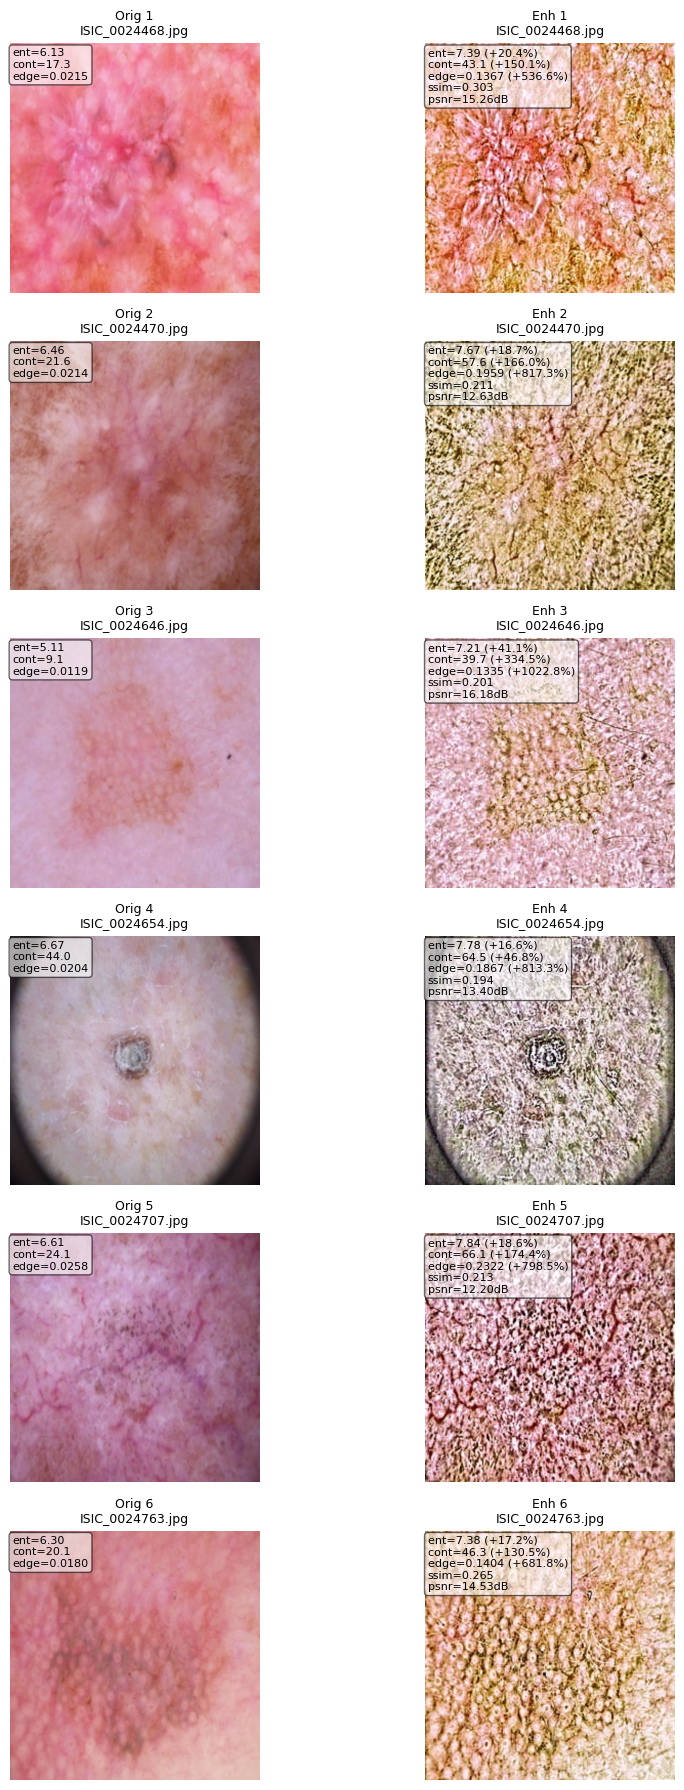

Metrics CSV saved to: /content/enhanced_images/preview_metrics.csv
Completed preview & analysis for 6 pairs.


In [2]:
# ====== DISPLAY & ANALYZE 6 ORIGINAL VS ENHANCED IMAGES ======
# Paste & run this cell in Colab after you have run the enhancement cell.
# It will find 6 matching pairs (original -> enhanced), show them side-by-side,
# compute metrics (entropy, contrast (std), edge strength, SSIM, PSNR) and save a CSV.

import os
from pathlib import Path
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from skimage.filters import sobel
from skimage.metrics import structural_similarity as ssim
from skimage.measure import shannon_entropy
import csv

# --- Helpers to locate folders (uses variables from previous cells if present) ---
def find_folder_hint(varname, candidates):
    if varname in globals():
        p = Path(globals()[varname])
        if p.exists():
            return p
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return None

# Try to use existing variables from your notebook
orig_root = find_folder_hint("extract_path", ["/content/unzipped_images", "/content/unzipped_images/"])
enh_root  = find_folder_hint("enh_root",  ["/content/enhanced_images", "/content/enhanced_images/","/content/drive/MyDrive/enhanced_images"])

if orig_root is None:
    # search /content and /content/drive for folders with images
    for root in ("/content", "/content/drive"):
        rootp = Path(root)
        if not rootp.exists(): continue
        for cand in rootp.rglob("*"):
            if cand.is_dir() and any(cand.rglob("*.jpg")):
                orig_root = cand
                break
        if orig_root: break

if enh_root is None:
    # try some fallback names
    for candidate in ["/content/enhanced_images","/content/drive/MyDrive/enhanced_images","/content/enhanced_images"]:
        p = Path(candidate)
        if p.exists():
            enh_root = p
            break

if orig_root is None or enh_root is None:
    raise FileNotFoundError("Could not auto-detect original or enhanced folders. Ensure `extract_path` and `enh_root` exist.")

print("Original folder:", orig_root)
print("Enhanced folder:", enh_root)

# collect lists
exts = (".jpg", ".jpeg", ".png", ".bmp", ".tiff")
orig_paths = sorted([str(p) for p in Path(orig_root).rglob("*") if p.suffix.lower() in exts])
enh_paths_all = sorted([str(p) for p in Path(enh_root).rglob("*") if p.suffix.lower() in exts])

if len(orig_paths) == 0:
    raise FileNotFoundError("No original images found in " + str(orig_root))
if len(enh_paths_all) == 0:
    raise FileNotFoundError("No enhanced images found in " + str(enh_root))

# Build 6 pairs: prefer same relative path, else match by filename, else fallback to first enhanced images
pairs = []
for p in orig_paths:
    if len(pairs) >= 6:
        break
    try:
        rel = Path(p).relative_to(orig_root)
        cand = enh_root.joinpath(rel)
        if cand.exists():
            pairs.append((p, str(cand)))
            continue
    except Exception:
        pass
    # match by filename
    fname = Path(p).name
    matches = [q for q in enh_paths_all if Path(q).name == fname]
    if matches:
        pairs.append((p, matches[0]))
        continue

# fallback if <6
if len(pairs) < 6:
    print(f"Only {len(pairs)} exact/filename matches found; filling remaining slots with first enhanced files.")
    needed = 6 - len(pairs)
    used_enh = set(e for _, e in pairs)
    idx = 0
    for o in orig_paths[:6]:
        if len(pairs) >= 6: break
        # try to find any enhanced not used yet
        for e in enh_paths_all:
            if e not in used_enh:
                pairs.append((o, e))
                used_enh.add(e)
                break

pairs = pairs[:6]
print("Displaying the following pairs (orig -> enhanced):")
for i,(o,e) in enumerate(pairs,1):
    print(f"{i}. {o} -> {e}")

# --- Metric functions (mirror HPO metrics) ---
def metrics_for_image_bgr(img_bgr):
    """Return (entropy, contrast_std, edge_mean) for BGR uint8 image"""
    try:
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    except Exception:
        # fallback if grayscale already
        gray = img_bgr if len(img_bgr.shape)==2 else cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    # entropy via skimage
    ent = float(shannon_entropy(gray))
    # contrast = std dev
    cont = float(np.std(gray.astype(np.float32)))
    # edge via sobel (skimage expects float)
    edge_map = sobel(gray.astype(np.float32) / 255.0)
    edge = float(np.mean(np.abs(edge_map)))
    return ent, cont, edge

def compute_psnr(img1, img2):
    """PSNR for two uint8 BGR images"""
    mse = np.mean((img1.astype(np.float32) - img2.astype(np.float32)) ** 2)
    if mse == 0:
        return float('inf')
    PIXEL_MAX = 255.0
    return 20 * np.log10(PIXEL_MAX / np.sqrt(mse))

def compute_ssim(img1, img2):
    """Compute SSIM; convert to grayscale for stability"""
    try:
        g1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
        g2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
    except Exception:
        g1 = img1 if img1.ndim==2 else cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
        g2 = img2 if img2.ndim==2 else cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
    # skimage's ssim expects float images in range 0..255 or 0..1; pass data_range=255
    val = ssim(g1, g2, data_range=255)
    return float(val)

# Prepare figure: 6 rows x 2 cols (original left, enhanced right)
n = len(pairs)
fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 3*n))
if n == 1:
    axes = np.expand_dims(axes, 0)

# CSV output
csv_path = Path(enh_root) / "preview_metrics.csv"
with open(csv_path, "w", newline='') as csvfile:
    writer = csv.writer(csvfile)
    header = ["index","orig_path","enh_path",
              "ent_orig","ent_enh","ent_rel_gain",
              "cont_orig","cont_enh","cont_rel_gain",
              "edge_orig","edge_enh","edge_rel_gain",
              "ssim","psnr"]
    writer.writerow(header)

    for i, (orig_p, enh_p) in enumerate(pairs):
        # load images (BGR uint8)
        img_o = cv2.imread(orig_p)
        img_e = cv2.imread(enh_p)
        if img_o is None:
            print("Failed to read original:", orig_p)
            img_o = np.zeros((224,224,3), dtype=np.uint8)
        if img_e is None:
            print("Failed to read enhanced:", enh_p)
            img_e = np.zeros_like(img_o)

        # resize display copies to width ~512 for nicer viewing (keep aspect)
        display_w = 512
        h_o, w_o = img_o.shape[:2]
        scale_o = display_w / float(w_o) if w_o>0 else 1.0
        disp_o = cv2.resize(img_o, (int(w_o*scale_o), int(h_o*scale_o))) if w_o>0 else img_o
        h_e, w_e = img_e.shape[:2]
        scale_e = display_w / float(w_e) if w_e>0 else 1.0
        disp_e = cv2.resize(img_e, (int(w_e*scale_e), int(h_e*scale_e))) if w_e>0 else img_e

        # compute metrics
        ent_o, cont_o, edge_o = metrics_for_image_bgr(img_o)
        ent_e, cont_e, edge_e = metrics_for_image_bgr(img_e)
        ent_rel = (ent_e - ent_o) / (ent_o + 1e-9)
        cont_rel = (cont_e - cont_o) / (cont_o + 1e-9)
        edge_rel = (edge_e - edge_o) / (edge_o + 1e-9)
        ssim_val = compute_ssim(img_o, img_e)
        psnr_val = compute_psnr(img_o, img_e)

        # write CSV row
        row = [i, orig_p, enh_p,
               ent_o, ent_e, ent_rel,
               cont_o, cont_e, cont_rel,
               edge_o, edge_e, edge_rel,
               ssim_val, psnr_val]
        writer.writerow(row)

        # display images and overlay text
        ax_o = axes[i,0]
        ax_e = axes[i,1]
        # Convert BGR->RGB for matplotlib
        ax_o.imshow(cv2.cvtColor(disp_o, cv2.COLOR_BGR2RGB))
        ax_o.set_title(f"Orig {i+1}\n{Path(orig_p).name}", fontsize=9)
        ax_o.axis("off")
        # Annotate metrics on original
        ax_o.text(0.01, 0.98, f"ent={ent_o:.2f}\ncont={cont_o:.1f}\nedge={edge_o:.4f}",
                  transform=ax_o.transAxes, fontsize=8, va='top', ha='left',
                  bbox=dict(facecolor='white', alpha=0.6, boxstyle='round,pad=0.3'))

        ax_e.imshow(cv2.cvtColor(disp_e, cv2.COLOR_BGR2RGB))
        ax_e.set_title(f"Enh {i+1}\n{Path(enh_p).name}", fontsize=9)
        ax_e.axis("off")
        # Annotate metrics on enhanced + relative gains and ssim/psnr
        ax_e.text(0.01, 0.98, f"ent={ent_e:.2f} ({ent_rel*100:+.1f}%)\ncont={cont_e:.1f} ({cont_rel*100:+.1f}%)\nedge={edge_e:.4f} ({edge_rel*100:+.1f}%)\nssim={ssim_val:.3f}\npsnr={psnr_val:.2f}dB",
                  transform=ax_e.transAxes, fontsize=8, va='top', ha='left',
                  bbox=dict(facecolor='white', alpha=0.6, boxstyle='round,pad=0.3'))

plt.tight_layout()
plt.show()

print("Metrics CSV saved to:", str(csv_path))
print("Completed preview & analysis for 6 pairs.")
